In [1]:
import torch
from torch import nn

In [84]:
network = nn.Sequential(
    nn.Linear(1, 1),
    nn.ReLU(),
)

In [85]:
print(network)

Sequential(
  (0): Linear(in_features=1, out_features=1, bias=True)
  (1): ReLU()
)


In [86]:
# with torch.no_grad():
#     network[0].weight.fill_(torch.tensor([1.0, 2.0, 3.0]))

In [108]:
with torch.no_grad():
    network[0].weight.fill_(-1.0)
    network[0].bias.fill_(1.0)

In [109]:
x = torch.tensor([[-2.0], [-1.0], [0.0], [1.0], [2.0], [4.0], [-3.0]])

In [110]:
print("weights:", network[0].weight)
print("bias:", network[0].bias)
print("outputs:", network(x).detach().squeeze())

weights: Parameter containing:
tensor([[-1.]], requires_grad=True)
bias: Parameter containing:
tensor([1.], requires_grad=True)
outputs: tensor([3., 2., 1., 0., 0., 0., 4.])


In [111]:
from torch.nn.functional import relu

In [112]:
relu(torch.tensor([-2.0]))

tensor([0.])

In [113]:
network1 = nn.Sequential(
    nn.Linear(1, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

In [243]:
with torch.no_grad():
    network1[0].weight[:] = torch.tensor([
        [1.0],
        [1.0],
        [1.0],
        [1.0]
    ])
    network1[0].bias[:] = torch.tensor([-2.0, -2.1, -4.9, -5.0])
    network1[2].weight[:] = torch.tensor([[10.0, -10.0, -10.0, 10.0]])
    network1[2].bias.zero_()

In [244]:
x = torch.tensor([[0.0], [1.0], [1.05], [1.5], 
                  [2.0], [2.05], [2.5], [2.95], 
                  [3.0], [3.05], [3.5], [3.95],
                  [4.0], [4.05], [4.5], [4.95],
                  [5.0]])

In [245]:
with torch.no_grad():
    y = network1(x)

In [246]:
for value, output in zip(x.squeeze(), y.squeeze()):
    print(f"x = {value.item():4.2f}  →  output = {output.item():.2f}")

x = 0.00  →  output = 0.00
x = 1.00  →  output = 0.00
x = 1.05  →  output = 0.00
x = 1.50  →  output = 0.00
x = 2.00  →  output = 0.00
x = 2.05  →  output = 0.50
x = 2.50  →  output = 1.00
x = 2.95  →  output = 1.00
x = 3.00  →  output = 1.00
x = 3.05  →  output = 1.00
x = 3.50  →  output = 1.00
x = 3.95  →  output = 1.00
x = 4.00  →  output = 1.00
x = 4.05  →  output = 1.00
x = 4.50  →  output = 1.00
x = 4.95  →  output = 0.50
x = 5.00  →  output = 0.00


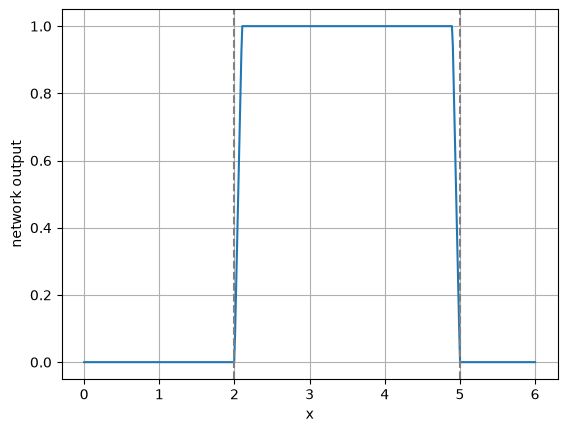

In [247]:
import matplotlib.pyplot as plt

x_plot = torch.linspace(0, 6, 500).unsqueeze(1)

with torch.no_grad():
    y_plot = network1(x_plot)

plt.plot(x_plot.numpy(), y_plot.numpy())
plt.axvline(2, color="grey", linestyle="--")
plt.axvline(5, color="grey", linestyle="--")
plt.xlabel("x")
plt.ylabel("network output")
plt.grid()
plt.show()

In [262]:
a = torch.tensor([
        [1.0],
        [1.0],
        [1.0],
        [1.0]
    ]) * torch.tensor([[2.5]])
a

tensor([[2.5000],
        [2.5000],
        [2.5000],
        [2.5000]])

In [263]:
b = torch.tensor([-2.0, -2.1, -4.9, -5.0])
m = a + b
m

tensor([[ 0.5000,  0.4000, -2.4000, -2.5000],
        [ 0.5000,  0.4000, -2.4000, -2.5000],
        [ 0.5000,  0.4000, -2.4000, -2.5000],
        [ 0.5000,  0.4000, -2.4000, -2.5000]])

In [264]:
y = relu(m)
y

tensor([[0.5000, 0.4000, 0.0000, 0.0000],
        [0.5000, 0.4000, 0.0000, 0.0000],
        [0.5000, 0.4000, 0.0000, 0.0000],
        [0.5000, 0.4000, 0.0000, 0.0000]])

In [265]:
o = torch.tensor([[10.0, -10.0, -10.0, 10.0]])


tensor([[ 5.0000, -4.0000, -0.0000,  0.0000],
        [ 5.0000, -4.0000, -0.0000,  0.0000],
        [ 5.0000, -4.0000, -0.0000,  0.0000],
        [ 5.0000, -4.0000, -0.0000,  0.0000]])

In [267]:
torch.tensor([2.0, 1.0, 2.0, 1.0]) * torch.tensor([1, -1, 1, -1]) + torch.tensor([-1.0, -1.0, -1.0, -1.0])

tensor([ 1., -2.,  1., -2.])

In [269]:
w = torch.tensor([
        [ 1.0, -1.0],  # left score  = paddle_position - ball_position
        [-1.0,  1.0],  # right score = ball_position - paddle_position
    ])

In [276]:
x = torch.tensor([[5.0, 2.0]])
x @ w.T

tensor([[ 3., -3.]])

In [273]:
import torch
from torch import nn

paddle = nn.Linear(2, 2)

with torch.no_grad():
    paddle.weight[:] = torch.tensor([
        [ 1.0, -1.0],  # left score  = paddle_position - ball_position
        [-1.0,  1.0],  # right score = ball_position - paddle_position
    ])
    paddle.bias.zero_()

positions = torch.tensor([
    [5.0, 2.0],  # ball is left
    [5.0, 8.0],  # ball is right
    [5.0, 5.0],  # aligned
])

with torch.no_grad():
    scores = paddle(positions)

for position, score in zip(positions, scores):
    print(f"paddle={position[0]:.0f}, ball={position[1]:.0f} → scores={score.tolist()}")

paddle=5, ball=2 → scores=[3.0, -3.0]
paddle=5, ball=8 → scores=[-3.0, 3.0]
paddle=5, ball=5 → scores=[0.0, 0.0]
